In [ ]:
## use this script for text analysis exercise and practicing with huggingface datasets

### TOKENIZATION

In [1]:
print('a')

a


In [3]:
!pip install transformers

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
    --------------------------------------- 0.3/13.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.1 MB 1.5 MB/s eta 0:00:09
   - -------------------------------------- 0.5/13.1 MB 1.5 MB/s eta 0:00:09
   - -------------------------------------- 0.5/13.1 MB 1.5 MB/s eta 0:00:09
   -- ------------------------------------- 0.8/13.1 MB 630.6 kB/s eta 0:00:20
   -- ------------------------------------- 0.8/13.1 MB 630.6 kB/s eta 0:00:20
   -- ------------------------------------- 0.8/13.1 MB 630.6 kB/s eta 0:00:20
   -- ------------------------------------- 0.8/13.1 MB 630.6 kB/s eta 0:00:20
   -- ------------------------------------- 0.8/13.1 MB 630.6 kB/s eta 0:00:20
   -- ------------------------------------- 0.8/13.1 MB 630.6 kB/s eta 0:00:20
   -- -


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\jared\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
!huggingface-cli login

'huggingface-cli' �����ڲ����ⲿ���Ҳ���ǿ����еĳ���
���������ļ���


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from torch.utils.data import DataLoader, TensorDataset

In [10]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
tokenizer("I'm making dumplings for dinner tonight", return_tensors="pt")
# {
#     'input_ids': ([[     2, 235277,  82913,    576,   2656,  30407, 235269,  11490,    970,  29871, 235265]]),
#     'attention_mask': ([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])
# }

{'input_ids': tensor([[  101,  1045,  1005,  1049,  2437, 15653, 11227,  2005,  4596,  3892,
           102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [12]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
input_ids = tokenizer.encode("I'm making dumplings for dinner tonight")
input_ids
# [2, 235277, 82913, 576, 2656, 30407, 235269, 11490, 970, 29871, 235265]

[101, 1045, 1005, 1049, 2437, 15653, 11227, 2005, 4596, 3892, 102]

In [13]:
tokenizer.decode(input_ids)

"[CLS] i ' m making dumplings for dinner tonight [SEP]"

In [14]:
tokenizer.decode(input_ids, skip_special_tokens=True)

"i ' m making dumplings for dinner tonight"

In [18]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
token_dict = tokenizer(
    [
        "im making dumplings tonight for dinner.",
        "A plane is flying overhead.",
        "Stock marketing is crashing!! I can't believe no one is reacting."
    ],
    return_tensors="pt",
    padding=True
)
tokenizer.decode(token_dict['input_ids'],skip_special_toekns=True)

['[CLS] im making dumplings tonight for dinner. [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]',
 '[CLS] a plane is flying overhead. [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]',
 "[CLS] stock marketing is crashing!! i can ' t believe no one is reacting. [SEP]"]

In [19]:
## BANKING 77 DATA

In [40]:
# pip install -U datasets pandas matplotlib

from datasets import load_dataset
import pandas as pd
import numpy as np

In [8]:
ds = load_dataset("PolyAI/banking77")
dict(ds)

{'train': Dataset({
     features: ['text', 'label'],
     num_rows: 10003
 }),
 'test': Dataset({
     features: ['text', 'label'],
     num_rows: 3080
 })}

In [9]:
next(iter(ds['train']))

{'text': 'I am still waiting on my card?', 'label': 11}

## EDA & TEXT CLEANING

In [10]:
train_df = ds['train'].to_pandas()
test_df = ds['test'].to_pandas()
label_names = ds["train"].features["label"].names

train_df["intent"] = train_df["label"].map(lambda x: label_names[x])
test_df['intent'] = test_df['label'].map(lambda x: label_names[x])

In [11]:
import sys
import torch
print("Python version:", sys.version)
print("CUDA is available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")
import torch, torchvision, torchaudio
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("torchaudio:", torchaudio.__version__)
print("CUDA available:", torch.cuda.is_available())

Python version: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
CUDA is available: True
GPU name: NVIDIA GeForce RTX 4080 SUPER
torch: 2.6.0+cu124
torchvision: 0.21.0+cu124
torchaudio: 2.6.0+cu124
CUDA available: True


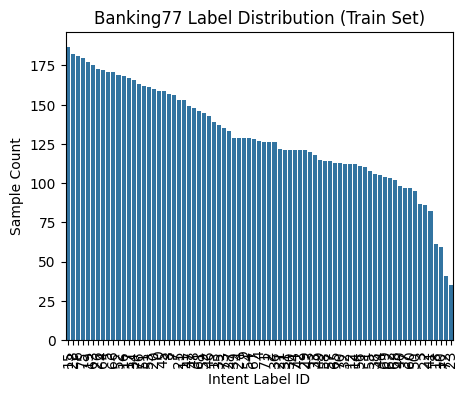

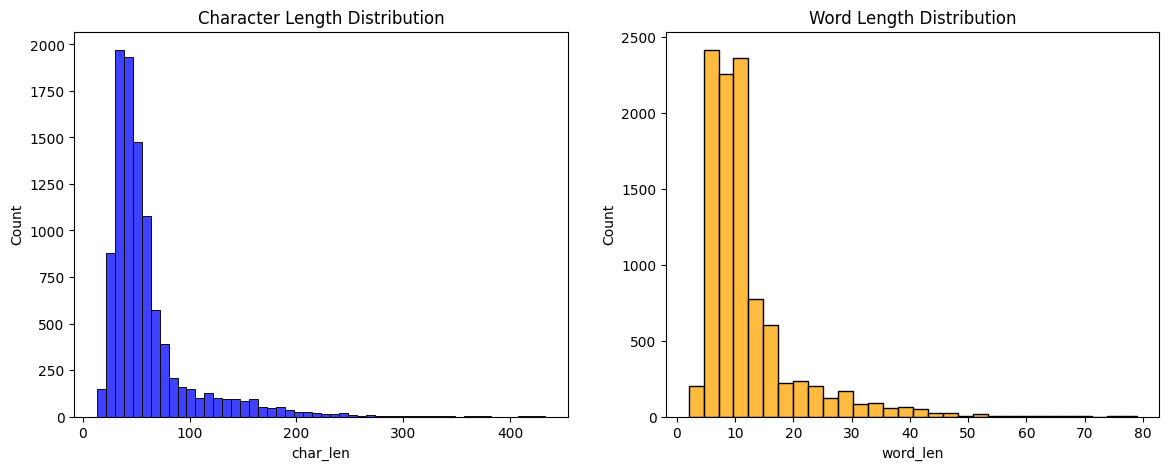

In [12]:
# !pip install datasets transformers sentence-transformers scikit-learn matplotlib seaborn pandas -q
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 3. Label Distribution (标签分布可视化)
plt.figure(figsize=(5, 4))
sns.countplot(x='label', data=train_df, order=train_df['label'].value_counts().index)
plt.title("Banking77 Label Distribution (Train Set)")
plt.xlabel("Intent Label ID")
plt.ylabel("Sample Count")
plt.xticks(rotation=90)
plt.show()

train_df['char_len'] = train_df['text'].apply(len)
train_df['word_len'] = train_df['text'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df['char_len'], bins=50, ax=axes[0], color='blue')
axes[0].set_title("Character Length Distribution")
sns.histplot(train_df['word_len'], bins=30, ax=axes[1], color='orange')
axes[1].set_title("Word Length Distribution")
plt.show()

In [13]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [14]:
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text, remove_stopwords=True):
    ## change it to lower case, remove HTML
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    # 2. remove punc
    text = text.translate(str.maketrans('', '', string.punctuation))
    # 3. remove space
    text = re.sub(r'\s+', ' ', text).strip()
    words = text.split()
    # 4. 停用词与 Lemmatization
    if remove_stopwords:
        words = [w for w in words if w not in stop_words]
    return ''.join(words)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jared\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\jared\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score,f1_score

In [42]:
## use TF-IDF to extract features
vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 3))
X_train = vectorizer.fit_transform(train_df['text'])
y_train = train_df['label']

X_test = vectorizer.transform(test_df['text'])
y_test = test_df['label']

model1 = LogisticRegression(max_iter=1000, C=1.0)
model1.fit(X_train, y_train)

y_pred = model1.predict(X_test)
print(f"TF-IDF + Logistic Regression Accuracy: {accuracy_score(y_test, y_pred):.4f}")

model2 = XGBClassifier(
    n_estimators=1000, 
    learning_rate=0.05, 
    max_depth=6, 
    random_state=42,
    device="cuda",
    tree_method="hist",
)
model2.fit(X_train, y_train)

y_pred = model2.predict(X_test)
print(f"TF-IDF + XGBClassifier Accuracy: {accuracy_score(y_test, y_pred):.4f}")

TF-IDF + Logistic Regression Accuracy: 0.8455
TF-IDF + XGBClassifier Accuracy: 0.8188


In [43]:
## use LLM embeddings in classifier
from sentence_transformers import SentenceTransformer
import numpy as np
model = SentenceTransformer('bert-base-uncased')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1015.46it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [44]:
X_train_emb = model.encode(train_df['text'].tolist(), show_progress_bar=True)
X_test_emb = model.encode(test_df['text'].tolist(), show_progress_bar=True)

# 训练 Logistic Regression
model1_embd = LogisticRegression(max_iter=1000)
model1_embd.fit(X_train_emb, y_train)

y_pred_emb = model1_embd.predict(X_test_emb)
print(f"SentenceTransformer Embedding + LR Accuracy: {accuracy_score(y_test, y_pred_emb):.4f}")

Batches: 100%|██████████| 97/97 [00:00<00:00, 100.44it/s]


SentenceTransformer Embedding + LR Accuracy: 0.8854


In [ ]:
model2_embd = XGBClassifier(
    n_estimators=1000, 
    learning_rate=0.05, 
    max_depth=6, 
    random_state=42,
    device="cuda",
    tree_method="hist",
)
model2_embd.fit(X_train_emb, y_train)
y_pred_embd = model2_embd.predict(X_test_emb)
print(f"SentenceTransformer Embd + XGBClassifier Accuracy: {accuracy_score(y_test, y_pred_embd):.4f}")

SentenceTransformer Embd + XGBClassifier Accuracy: 0.7977


C:\Users\jared\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\jared\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [52]:
help(tokenizer)

Help on BertTokenizer in module transformers.models.bert.tokenization_bert object:

class BertTokenizer(transformers.tokenization_utils_tokenizers.TokenizersBackend)
 |  BertTokenizer(
 |      vocab: str | dict[str, int] | None = None,
 |      do_lower_case: bool = True,
 |      unk_token: str = '[UNK]',
 |      sep_token: str = '[SEP]',
 |      pad_token: str = '[PAD]',
 |      cls_token: str = '[CLS]',
 |      mask_token: str = '[MASK]',
 |      tokenize_chinese_chars: bool = True,
 |      strip_accents: bool | None = None,
 |      **kwargs
 |  )
 |
 |  Construct a BERT tokenizer (backed by HuggingFace's tokenizers library). Based on WordPiece.
 |
 |  This tokenizer inherits from [`TokenizersBackend`] which contains most of the main methods. Users should refer to
 |  this superclass for more information regarding those methods.
 |
 |  Args:
 |      vocab (`str` or `dict[str, int]`, *optional*):
 |          Custom vocabulary dictionary. If not provided, vocabulary is loaded from `voca

In [55]:
train_df.columns

Index(['text', 'label', 'intent', 'char_len', 'word_len'], dtype='object')

In [49]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

train_ds = Dataset.from_pandas(train_df[['text', 'label']])
test_ds = Dataset.from_pandas(test_df[['text', 'label']])

train_tokenized = train_ds.map(lambda x : tokenizer(x['text'],padding='max_length',truncation=True), batched=True)
test_tokenized = test_ds.map(lambda x : tokenizer(x['text'],padding='max_length',truncation=True), batched=True)

Map: 100%|██████████| 3080/3080 [00:00<00:00, 6489.43 examples/s]


In [50]:
train_ds

Dataset({
    features: ['text', 'label'],
    num_rows: 10003
})

In [51]:
train_tokenized.features

{'text': Value('string'),
 'label': Value('int64'),
 'input_ids': List(Value('int32')),
 'token_type_ids': List(Value('int8')),
 'attention_mask': List(Value('int8'))}

In [54]:
help(AutoModelForSequenceClassification.from_pretrained)

Help on method from_pretrained in module transformers.models.auto.auto_factory:

from_pretrained(*model_args, **kwargs) class method of transformers.models.auto.modeling_auto.AutoModelForSequenceClassification
    Instantiate one of the model classes of the library (with a sequence classification head) from a pretrained model.

    The model class to instantiate is selected based on the `model_type` property of the config object (either
    passed as an argument or loaded from `pretrained_model_name_or_path` if possible), or when it's missing, by
    falling back to using pattern matching on `pretrained_model_name_or_path`:

        - **albert** -- [`AlbertForSequenceClassification`] (AlbertConfig model)
        - **arcee** -- [`ArceeForSequenceClassification`] (ArceeConfig model)
        - **axk1** -- [`AXK1ForSequenceClassification`] (AXK1Config model)
        - **axk2** -- [`AXK2ForSequenceClassification`] (AXK2Config model)
        - **bart** -- [`BartForSequenceClassification`] (B

### LoRA Fine Tuning 

In [ ]:

from peft import LoraConfig, get_peft_model, TaskType
from transformers import AutoModelForSequenceClassification, Trainer

base_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=77) ## num of class head
print(base_model)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1813.35it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [55]:
import accelerate
print("Accelerate version:", accelerate.__version__)

Accelerate version: 1.15.0


In [56]:
print(train_tokenized[0])

{'text': 'I am still waiting on my card?', 'label': 11, 'input_ids': [101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [ ]:

peft_config = LoraConfig(
    r=8,     ##higher r means more trainable params         
    lora_alpha=32,   ## LoRA impact to baseline model
    target_modules=["q_lin", "v_lin"], ## use Q,V layer for finetunning as encoders are informative
    lora_dropout=0.1,
    bias="none",
    task_type = TaskType.SEQ_CLS
)

training_args = TrainingArguments(
    output_dir="./results",             
    num_train_epochs=8,                 
    per_device_train_batch_size=16,    
    per_device_eval_batch_size=16,     
    learning_rate=0.0001,                
    weight_decay=0.01,                  
    eval_strategy="epoch",              
    save_strategy="epoch",             
    load_best_model_at_end=True,               
    logging_steps=10,                   
    fp16=True,                          
                
)

model = get_peft_model(base_model, peft_config) ## Parameter-Efficient Fine-Tuning 

model.print_trainable_parameters()  
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized
)


trainable params: 797,261 || all params: 67,809,946 || trainable%: 1.1757


C:\Users\jared\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\peft\mapping_func.py:148: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
C:\Users\jared\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\peft\tuners\tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


In [80]:
batch = next(iter(trainer.get_train_dataloader()))
print("Batch keys：", batch.keys())
print("Batch Labels：", batch["labels"])

Batch keys： dict_keys(['labels', 'input_ids', 'attention_mask'])
Batch Labels： tensor([45, 47, 59, 63, 29, 64, 13, 71, 13, 67, 34, 66, 47,  6, 26,  9],
       device='cuda:0')


In [82]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,4.271802,4.287662
2,3.647608,3.743780
3,2.560139,2.469219
4,1.733579,1.691603
5,1.481046,1.336306
6,1.197126,1.156379
7,1.154057,1.056901
8,0.883743,1.030015


TrainOutput(global_step=5008, training_loss=2.3351353549728757, metrics={'train_runtime': 257.8641, 'train_samples_per_second': 310.334, 'train_steps_per_second': 19.421, 'total_flos': 1.0810743214129152e+16, 'train_loss': 2.3351353549728757, 'epoch': 8.0})

In [83]:
## Evaluate fine tuned model
result = trainer.evaluate(eval_dataset=test_tokenized)
print(result)

Training Loss,Validation Loss,Epoch
0.883743,1.030015,8


{'eval_loss': 1.030015468597412}


In [84]:
train_df.head()

,text,label,intent,char_len,word_len
0,I am still waiting on my card?,11,card_arrival,30,7
1,What can I do if my card still hasn't arrived ...,11,card_arrival,60,13
2,I have been waiting over a week. Is the card s...,11,card_arrival,58,12
3,Can I track my card while it is in the process...,11,card_arrival,59,13
4,"How do I know if I will get my card, or if it ...",11,card_arrival,54,15


In [85]:
pred_output = trainer.predict(test_tokenized)
display("structure", pred_output.__annotations__)

'structure'

{'predictions': numpy.ndarray | tuple[numpy.ndarray],
 'label_ids': numpy.ndarray | tuple[numpy.ndarray] | None,
 'metrics': dict[str, float] | None}

In [86]:
pred_output.label_ids

array([11, 11, 11, ..., 24, 24, 24], shape=(3080,))

In [87]:
display('test shape: ', test_tokenized.shape,
    "pred shape:", pred_output.predictions.shape)

'test shape: '

(3080, 5)

'pred shape:'

(3080, 77)

In [88]:
len(y_pred)

3080

In [94]:
pred_output.predictions[1]

array([-16.09375 , -23.390625, -26.390625, -23.96875 , -23.6875  ,
       -23.703125, -22.46875 , -24.3125  , -24.015625, -16.46875 ,
       -22.      , -13.234375, -18.484375, -15.71875 , -17.28125 ,
       -23.34375 , -20.09375 , -24.890625, -22.71875 , -26.359375,
       -19.859375, -22.859375, -18.1875  , -19.59375 , -24.296875,
       -18.578125, -20.96875 , -20.15625 , -23.6875  , -22.4375  ,
       -19.875   , -27.71875 , -29.703125, -27.625   , -22.953125,
       -27.8125  , -30.34375 , -23.421875, -22.390625, -20.296875,
       -20.640625, -17.46875 , -18.703125, -20.125   , -20.640625,
       -21.203125, -23.640625, -19.765625, -20.984375, -21.140625,
       -27.390625, -23.640625, -22.828125, -19.453125, -23.765625,
       -21.3125  , -23.4375  , -24.953125, -24.078125, -18.640625,
       -26.5625  , -22.796875, -22.09375 , -17.984375, -24.921875,
       -28.53125 , -19.859375, -22.265625, -21.515625, -25.15625 ,
       -25.421875, -23.1875  , -22.03125 , -21.390625, -22.156

In [95]:
np.argmax(pred_output.predictions[1],axis=-1)

np.int64(11)

In [96]:
pred_output.label_ids

array([11, 11, 11, ..., 24, 24, 24], shape=(3080,))

In [ ]:
y_pred = np.argmax(pred_output.predictions, axis=-1)
y_true = pred_output.label_ids

print("Accuracy:", accuracy_score(y_true, y_pred))
## more flexible after fine tuning

Accuracy: 0.7425324675324675


In [98]:
print("Weighted F1:", f1_score(y_true, y_pred, average="weighted"))
print(classification_report(y_true, y_pred, zero_division=0))

Weighted F1: 0.7286069344859654
              precision    recall  f1-score   support

           0       0.82      0.90      0.86        40
           1       0.93      0.93      0.93        40
           2       0.95      0.97      0.96        40
           3       0.74      0.80      0.77        40
           4       0.83      0.50      0.62        40
           5       0.79      0.65      0.71        40
           6       0.78      0.88      0.82        40
           7       0.88      0.72      0.79        40
           8       0.89      0.82      0.86        40
           9       0.97      0.85      0.91        40
          10       1.00      0.03      0.05        40
          11       0.64      0.80      0.71        40
          12       0.72      0.70      0.71        40
          13       0.86      0.90      0.88        40
          14       0.65      0.90      0.76        40
          15       0.64      0.88      0.74        40
          16       0.61      0.57      0.59      

### DoRA Fine Tunining - To solve the problem of LoRA in Direction change